# Refinamiento por gradiente conjugado con modelo del dispositivo

**Pregunta:** ¿Hacen unos pocos pasos de gradiente conjugado a través del modelo del dispositivo, dados desde un inicio de Gerchberg-Saxton ponderado, que las trampas de un SLM con crosstalk queden uniformes, y se debe su ganancia al modelo del dispositivo o a la pérdida que Schroff et al. (2023) ya publicaron?

- **Nivel:** 4, Métodos propuestos
- **Requisitos previos:** notebooks 02 y 03 de este tema y notebook 01 del tema 01
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Todo método de los notebooks hasta aquí calcula un holograma para un SLM ideal y confía en el resultado. Un SLM real cuantiza la fase, la difumina entre píxeles vecinos (el crosstalk del cristal líquido), tiene un factor de llenado menor que 1 y parpadea. La respuesta habitual es una cámara en el lazo, que corrige las trampas después. El refinamiento por gradiente conjugado con modelo del dispositivo del producto plantea otra pregunta: partir de un holograma de Gerchberg-Saxton ponderado y dar pasos de gradiente conjugado sobre una pérdida calculada a través del modelo del dispositivo, de modo que el holograma se calcule para el dispositivo. Primero verás cuán equivocado está sobre su propio resultado un método de modelo ideal en el dispositivo del caso C08, luego ejecutarás las líneas base más fuertes que ofrece la literatura, Gerchberg-Saxton ponderado de fase fija y gradiente conjugado a través del operador de crosstalk, y después el refinamiento mismo, con dos semillas y luego con ocho. Dos variantes prueban a qué se debe su ganancia: la actualización multiplicativa de pesos del lazo ponderado, que el refinamiento ya no aplica por defecto, y la pérdida de error normalizado de Schroff et al., el método publicado más cercano. La última medición encuentra dónde vive la ventaja y dónde cuesta.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import device_of, setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import Device, device_focal_field
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import ring
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b1_device_wgs
from pipeline.model.holo.methods.optim import m13_crosstalk_cg

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def on_device(phi, setup, traps, device):
    """Eficiencia, uniformidad y dispersión (%) de un holograma en el dispositivo, media de cuatro sorteos."""
    rows = []
    for draw in range(4):
        field = device_focal_field(phi, setup, device, Rng(draw))
        i = metrics.trap_intensities(forward.trap_fields_from_fft(field, setup, traps))
        rows.append((metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)))
    return np.mean(rows, axis=0)

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio; los parámetros de crosstalk son los ajustados por Schroff et al. 2023 (https://doi.org/10.1038/s41598-023-30296-6).
- Archivo leído: `data/examples/cases.json`, caso C08: 64 trampas sobre un SLM de 128 por 128 píxeles con 4 bits de fase, crosstalk de ancho ajustado 1,24 y exponente 1,8, un factor de llenado de 0,85 y un parpadeo de 0,05 rad, y dos semillas contadas desde la semilla del caso.

In [2]:
# caso C08: 64 trampas en un SLM de 128 x 128 píxeles con 4 bits, crosstalk de píxel, factor de llenado 0.85 y algo de
# parpadeo
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C08_device_limited"]
setup = setup_of(rec)
device = device_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(rec["budget"]["iterations"])
seeds = [rec["seed"], rec["seed"] + 1]
print(f"{len(traps)} trampas, {setup.n_pix} x {setup.n_pix} píxeles, {device.bit_depth} bits,")
print(f"crosstalk (sigma, q): {device.crosstalk}")
print(f"factor de llenado {device.fill_factor}, parpadeo {device.flicker_rad} rad")

64 trampas, 128 x 128 píxeles, 4 bits,
crosstalk (sigma, q): (1.24, 1.8)
factor de llenado 0.85, parpadeo 0.05 rad


## Método

El modelo de dispositivo del producto actúa sobre la fase mostrada en cuatro pasos: cuantización a $2^b$ niveles, una curva de respuesta, ruido de parpadeo y el crosstalk, una convolución circular de la fase sobremuestreada con un núcleo cuya función de transferencia es $\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]$, seguido de la apertura del píxel (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). Un holograma se juzga por el campo focal de esa fase mostrada. Los métodos de los notebooks anteriores no conocen el dispositivo: Gerchberg-Saxton ponderado de fase fija (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) itera el modelo ideal y se detiene cuando es uniforme en el modelo ideal. Las métricas son las del tema 01, calculadas en el dispositivo y promediadas sobre cuatro sorteos del parpadeo, porque el parpadeo es aleatorio y un holograma debe ser bueno en el dispositivo promedio.

El modelo del dispositivo y la pérdida que minimiza el refinamiento se escriben aquí como ecuaciones destacadas, a partir del registro de diseño del método en el producto. El SLM no muestra la fase $\phi$ que calcula el método sino $\phi^{\text{disp}}=K * \big(Q_b(\phi)+\xi\big)$: la fase se redondea al más cercano de $L=2^b$ niveles con el cuantizador $Q_b$, se agrega un parpadeo aleatorio $\xi\sim\mathcal N(0,\sigma_f^2)$ y el resultado se difumina con el núcleo de crosstalk $K$ del cristal líquido, cuya función de transferencia sobre las frecuencias espaciales $(k_x,k_y)$ es

$$\widehat K(k_x,k_y)=\exp\!\Big[-\frac{|k_x|^{q}+|k_y|^{q}}{\sigma^{q}}\Big],$$

con $\sigma$ el ancho, ajustado por Schroff et al. en $1,24\ \mathrm{px}^{-1}$ con $q=1,80$ (de modo que un $\sigma$ menor es un difuminado más fuerte), y $q$ la nitidez de la caída (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). La fuente da $\sigma$ en píxeles inversos y no define más la unidad de la frecuencia; DinHot lee la frecuencia en ciclos por píxel del SLM, de modo que la grilla abarca más y menos un medio, y todo lo que este notebook dice del crosstalk es relativo a este modelo de dispositivo y no a un instrumento medido. El campo en las trampas es entonces $V=\mathrm{Op}(\phi)$, la transformada de Fourier de la fase mostrada por la envolvente del píxel $\eta$ del tema 01. La pérdida que el refinamiento reduce con sus pasos de gradiente conjugado es el error cuadrático relativo de las intensidades de las trampas respecto de los objetivos,

$$L(\phi)=\frac{\sum_m\big(|V_m(\phi)|^2-T_m\big)^2}{\sum_m T_m^2},\qquad T_m=\eta_0\,\frac{(w_m a_m)^2}{\sum_k (w_k a_k)^2},\qquad \eta_0=\sum_m|V_m|^2,$$

donde $a_m$ son las amplitudes de diseño de las trampas y $\eta_0$ es la potencia que las trampas tienen en ese momento, de modo que la pérdida pide una redistribución entre las trampas y no más potencia total. Los $w_m$ son los pesos de Gerchberg-Saxton ponderado. Por defecto el refinamiento deja todos los $w_m=1$, de modo que los pasos ajustan la eficiencia actual con objetivos iguales; con la opción `weights=True` aplica antes de cada iteración externa la actualización multiplicativa $w_m\leftarrow w_m\langle r\rangle/r_m$ con $r_m=|V_m|/a_m$ leído en el campo del dispositivo y no en el ideal, que es la forma que el producto tuvo hasta 0.02.003. La pérdida publicada más cercana es la de error normalizado de Schroff et al. (2023, ecuación 3),

$$C(\phi)=s\sum_m\big(\tilde T_m-\tilde I_m\big)^2,\qquad \tilde I_m=\frac{I_m}{\sum_k I_k},\quad \tilde T_m=\frac{T_m}{\sum_k T_k},\qquad I_m=|V_m|^2,$$

con $s$ una pendiente que solo reescala $C$ (el valor por defecto del producto hace de $C$ el error cuadrático relativo, de modo que las dos pérdidas tienen la misma escala). La opción `loss="normalized-error"` la ejecuta con el mismo modelo del dispositivo, el mismo inicio, el mismo optimizador y la misma salvaguarda del mejor iterado que la otra pérdida, de modo que las dos no difieren en nada más. Es invariante a la potencia total, así que no sostiene la eficiencia por sí sola: lo hace la salvaguarda. El gradiente de cualquiera de las dos pasa por $Q_b$ con el estimador straight-through (el cuantizador se trata como la identidad en el paso hacia atrás) y por $K$ con la convolución adjunta. Las afirmaciones se prueban con razones de dispersiones medidas, con la notación de los notebooks anteriores, $\rho=\sigma_{\text{GS ponderado con fase fija}}/\sigma_{\text{refinamiento}}$, ambas leídas en el dispositivo y promediadas sobre cuatro sorteos del parpadeo; $\rho>1$ significa que el refinamiento es más uniforme.

La primera celda ejecuta Gerchberg-Saxton ponderado y Gerchberg-Saxton ponderado de fase fija durante las 30 iteraciones del caso e imprime dos lecturas del mismo holograma: la dispersión que el método ve en el modelo ideal, que es la última entrada de su historial, y la dispersión que muestra el dispositivo.

In [3]:
# el modelo ideal frente al dispositivo: GS ponderado y WGS de fase fija se juzgan sobre el modelo ideal
ideal_runs = {}
for name, method in (("GS ponderado", m06_gsw), ("GS ponderado con fase fija", m07_phase_fixed_wgs)):
    ideal_runs[name] = method.run(setup, target, budget=budget, rng=Rng(seeds[0]))
    last = ideal_runs[name].history[-1]
    shown = on_device(ideal_runs[name].phi, setup, traps, device)
    print(f"{name}: juicio propio sobre el modelo ideal: sigma = {last['rel_std']:.3f} %, e = {last['efficiency']:.4f}")
    print(f"     en el dispositivo: sigma = {shown[2]:.3f} %, e = {shown[0]:.4f}")

GS ponderado: juicio propio sobre el modelo ideal: sigma = 1.262 %, e = 0.8018
     en el dispositivo: sigma = 14.424 %, e = 0.6812
GS ponderado con fase fija: juicio propio sobre el modelo ideal: sigma = 0.005 %, e = 0.7958
     en el dispositivo: sigma = 13.349 %, e = 0.6761


Una respuesta natural es que el método no ha iterado lo suficiente. La celda ejecuta GS ponderado con fase fija durante 100 iteraciones y lo lee en el dispositivo junto al holograma de 30 iteraciones.

In [4]:
# más iteraciones del método del modelo ideal no ayudan: 100 iteraciones de WGS de fase fija, leídas en el dispositivo
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(seeds[0]))
for label, res in (("30", ideal_runs["GS ponderado con fase fija"]), ("100", long_run)):
    shown = on_device(res.phi, setup, traps, device)
    print(f"GS ponderado con fase fija {label:>3s} iteraciones: en el dispositivo: sigma = {shown[2]:.3f} %")
    print(f"     u = {shown[1]:.4f}, e = {shown[0]:.4f}")

GS ponderado con fase fija  30 iteraciones: en el dispositivo: sigma = 13.349 %
     u = 0.6922, e = 0.6761
GS ponderado con fase fija 100 iteraciones: en el dispositivo: sigma = 13.349 %
     u = 0.6922, e = 0.6761


## Comparación

Dos líneas de trabajo responden a la brecha. La primera es la retroalimentación con cámara, que corrige las trampas después de hacer el holograma (Nogrette et al. 2014, https://arxiv.org/abs/1402.5329, llevan una dispersión rms de 19 por ciento a 1,4 por ciento en 20 iteraciones) y que el producto emula en notebooks de los temas posteriores. La segunda pone el modelo de crosstalk dentro de la optimización: Schroff et al. (2023) lo usan con gradiente conjugado en potenciales moldeados, y CG con modelo del dispositivo del producto es ese método para las trampas de este caso, con el gradiente a través de la adjunta del operador de crosstalk en forma cerrada. Es la línea base más fuerte para un dispositivo con crosstalk, pues optimiza directamente la intensidad consciente del dispositivo, al precio de muchas iteraciones; la línea base más fuerte para el modelo ideal es Gerchberg-Saxton ponderado de fase fija. La celda ejecuta CG con modelo del dispositivo en el dispositivo e imprime la dispersión, la uniformidad y la eficiencia en el dispositivo.

El refinamiento con modelo del dispositivo no parte en frío: primero corre 12 iteraciones de Gerchberg-Saxton ponderado del modelo ideal desde la superposición aleatoria de su semilla, y luego 4 iteraciones externas de 3 pasos de gradiente conjugado. Una prueba justa de la línea base más fuerte da a CG con modelo del dispositivo el mismo inicio y el mismo número de pasos de gradiente conjugado: la celda calcula ese inicio con GS ponderado (12 iteraciones, la misma semilla, por lo tanto la misma fase desde la que parte el refinamiento con modelo del dispositivo), corre CG con modelo del dispositivo durante 12 iteraciones desde él con el dispositivo del caso y lee el resultado en el dispositivo. También corre CG con modelo del dispositivo durante 12 iteraciones desde su propio inicio aleatorio, para mostrar cuánto vale el inicio para el gradiente conjugado. La celda también corre CG con modelo del dispositivo durante 40 iteraciones desde el mismo inicio, para ver si más iteraciones bajarían su dispersión, y repite la corrida de 12 iteraciones desde el inicio de la segunda semilla, de modo que la comparación con el refinamiento con modelo del dispositivo se apoye en dos semillas. El presupuesto igual es la comparación que hace este notebook.

In [5]:
# la otra manera de usar el modelo del dispositivo: gradiente conjugado a través del operador de crosstalk,
# 12 iteraciones, desde el inicio del refinamiento con modelo del dispositivo de cada semilla (12 iteraciones de GS
# ponderado,
# misma semilla) y, en contraste,
# desde su propio inicio aleatorio
warm_starts = [m06_gsw.run(setup, target, budget=Budget(12), rng=Rng(s)).phi for s in seeds]
cg_runs = [
    m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(s), init=w)
    for s, w in zip(seeds, warm_starts)
]
cg_all = np.array([on_device(r.phi, setup, traps, device) for r in cg_runs])
cg_numbers = cg_all[0]
cold_run = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(seeds[0]))
cg_cold = on_device(cold_run.phi, setup, traps, device)
for label, row in (("desde el inicio del refinamiento con modelo del dispositivo", cg_numbers),
                   ("desde un inicio aleatorio", cg_cold)):
    print(f"CG con modelo del dispositivo 12 iteraciones {label}: en el dispositivo: sigma = {row[2]:.3f} %, u "
          f"= {row[1]:.4f}, e = {row[0]:.4f}")
row = cg_all[1]
print("CG con modelo del dispositivo 12 iteraciones desde el inicio del refinamiento con modelo del dispositivo, "
    "segunda "
      f"semilla: sigma = {row[2]:.3f} %, "
      f"u = {row[1]:.4f}, e = {row[0]:.4f}")
# ¿bajan más iteraciones la dispersión de CG con modelo del dispositivo? 40 iteraciones desde el mismo inicio de la
# primera semilla
long_cg = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(40), rng=Rng(seeds[0]), init=warm_starts[0])
long_row = on_device(long_cg.phi, setup, traps, device)
print("CG con modelo del dispositivo 40 iteraciones desde el inicio del refinamiento con modelo del dispositivo: "
    "sigma = "
      f"{long_row[2]:.3f} %, "
      f"u = {long_row[1]:.4f}, e = {long_row[0]:.4f}")


CG con modelo del dispositivo 12 iteraciones desde el inicio del refinamiento con modelo del dispositivo: en el dispositivo: sigma = 8.349 %, u = 0.8211, e = 0.6712
CG con modelo del dispositivo 12 iteraciones desde un inicio aleatorio: en el dispositivo: sigma = 57.314 %, u = 0.0054, e = 0.2001
CG con modelo del dispositivo 12 iteraciones desde el inicio del refinamiento con modelo del dispositivo, segunda semilla: sigma = 7.743 %, u = 0.8252, e = 0.6768
CG con modelo del dispositivo 40 iteraciones desde el inicio del refinamiento con modelo del dispositivo: sigma = 8.508 %, u = 0.8202, e = 0.6715


## Evidencia

La afirmación del refinamiento por gradiente conjugado con modelo del dispositivo: después de un inicio de Gerchberg-Saxton ponderado, unos pocos pasos de gradiente conjugado sobre la pérdida de intensidad, a través del cuantizador de paso directo y del operador de crosstalk, dejan las trampas más uniformes en el dispositivo de lo que puede cualquier método de modelo ideal, y la ganancia viene del modelo del dispositivo en el lazo y de los pasos de gradiente conjugado, no de la actualización de pesos del lazo ponderado (Di Leonardo et al. 2007, ecuación 18) ni de la pérdida particular. La brecha que llena es que el modelo de crosstalk se había usado con gradiente conjugado en potenciales moldeados (Schroff et al. 2023) y dentro de un lazo ponderado que reemplaza solo amplitudes (Persson et al. 2012, https://doi.org/10.1364/OE.20.022334), pero no con una actualización de fase por gradiente conjugado después de un inicio ponderado para arreglos de trampas. El componente es `b1_device_wgs` en el código (el módulo conserva el identificador del método de cuando era un lazo ponderado). El refinamiento devuelve su mejor iterado y no el último: entre los iterados que conservan al menos 0,9 de la eficiencia del arranque, aquel cuya dispersión en su propio modelo de dispositivo es la más baja, el arranque incluido. La regla existe porque, con la actualización de pesos activa, una semilla de cada dos se desbocó en una red del benchmark (los pesos se abrieron a una razón de cerca de 1000 y la eficiencia cayó de 0,50 a 0,03, el registro del módulo del 2026-10-30), y una corrida que converge devuelve su último iterado o uno cercano, lo que muestra el iterado impreso de cada corrida más abajo. Las pruebas que siguen son las que pueden refutar la afirmación: dos semillas, y luego ocho, contra Gerchberg-Saxton ponderado de fase fija; una semilla contra el gradiente conjugado con el dispositivo desde el mismo inicio y con el mismo número de pasos de gradiente; las dos variantes, con la actualización de pesos y con la pérdida de Schroff et al., en las mismas ocho semillas; y un recorrido de la intensidad del crosstalk para ver de dónde viene la ventaja y qué cuesta.

La celda ejecuta el refinamiento con modelo del dispositivo, con 4 iteraciones externas de 3 pasos de gradiente conjugado cada una, para las dos semillas, y GS ponderado con fase fija para las mismas semillas, lee ambos en el dispositivo e imprime el promedio, el rango de la dispersión y las razones.

In [6]:
# la afirmación, el refinamiento con modelo del dispositivo: GS ponderado cuya actualización de fase son unos pocos
# pasos de
# gradiente conjugado a través
# del modelo del dispositivo
b1_runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in seeds]
b1_numbers = np.array([on_device(r.phi, setup, traps, device) for r in b1_runs])
m07_runs = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
m07_numbers = np.array([on_device(r.phi, setup, traps, device) for r in m07_runs])
for name, rows in (("GS ponderado con fase fija", m07_numbers), ("Refinamiento con modelo del "
    "dispositivo", b1_numbers)):
    e, u, sigma = rows.mean(axis=0)
    low, high = rows[:, 2].min(), rows[:, 2].max()
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.3f} % (rango {low:.3f} a {high:.3f})")
ratio = m07_numbers[:, 2].mean() / b1_numbers[:, 2].mean()
print(f"dispersión de GS ponderado con fase fija sobre la del refinamiento con modelo del dispositivo: {ratio:.1f}")
print("eficiencia del refinamiento con modelo del dispositivo sobre la de GS ponderado con fase fija: "
      f"{b1_numbers[:, 0].mean() / m07_numbers[:, 0].mean():.3f}")
print("razón de dispersión CG con modelo del dispositivo / el refinamiento con modelo del dispositivo (mismo inicio y "
      f"pasos), primera semilla: {cg_numbers[2] / b1_numbers[0, 2]:.2f}")
print("eficiencia del refinamiento con modelo del dispositivo sobre la de CG con modelo del dispositivo con la primera "
      f"semilla: {b1_numbers[0, 0] / cg_numbers[0]:.3f}")
ratios = cg_all[:, 2] / b1_numbers[:, 2]
print("razón de dispersión CG con modelo del dispositivo / el refinamiento con modelo del dispositivo (mismo inicio y "
      "pasos), por semilla: " + ", ".join(f"{x:.2f}" for x in ratios))
print("eficiencia del refinamiento con modelo del dispositivo sobre la de CG con modelo del dispositivo, por semilla: "
      + ", ".join(f"{x:.3f}" for x in b1_numbers[:, 0] / cg_all[:, 0]))

GS ponderado con fase fija: e = 0.6785, u = 0.7086, sigma = 13.132 % (rango 12.915 a 13.349)
Refinamiento con modelo del dispositivo: e = 0.6634, u = 0.8637, sigma = 6.240 % (rango 5.696 a 6.785)
dispersión de GS ponderado con fase fija sobre la del refinamiento con modelo del dispositivo: 2.1
eficiencia del refinamiento con modelo del dispositivo sobre la de GS ponderado con fase fija: 0.978
razón de dispersión CG con modelo del dispositivo / el refinamiento con modelo del dispositivo (mismo inicio y pasos), primera semilla: 1.23
eficiencia del refinamiento con modelo del dispositivo sobre la de CG con modelo del dispositivo con la primera semilla: 0.985
razón de dispersión CG con modelo del dispositivo / el refinamiento con modelo del dispositivo (mismo inicio y pasos), por semilla: 1.23, 1.36
eficiencia del refinamiento con modelo del dispositivo sobre la de CG con modelo del dispositivo, por semilla: 0.985, 0.984


Dos semillas dan un rango y no un intervalo, así que la celda siguiente repite la comparación del refinamiento con modelo del dispositivo y GS ponderado con fase fija con ocho semillas, las dos de arriba y seis más, e imprime la mediana de la razón de las dispersiones con un intervalo bootstrap, la eficiencia que paga el refinamiento con modelo del dispositivo y el iterado que devuelve.

In [7]:
# más semillas: el refinamiento con modelo del dispositivo y GS ponderado con fase fija con ocho semillas, las dos de
# arriba y
# seis más, leídos en el dispositivo
extra = [rec["seed"] + k for k in range(2, 8)]
more_b1 = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in extra]
more_m07 = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in extra]
b1_all = np.vstack([b1_numbers, [on_device(r.phi, setup, traps, device) for r in more_b1]])
m07_all = np.vstack([m07_numbers, [on_device(r.phi, setup, traps, device) for r in more_m07]])
ratio_all = m07_all[:, 2] / b1_all[:, 2]
eff_all = b1_all[:, 0] / m07_all[:, 0]
boot = np.random.default_rng(0)
medians = [np.median(boot.choice(ratio_all, len(ratio_all))) for _ in range(2000)]
low, high = np.percentile(medians, [2.5, 97.5])
returned = [r.meta["best_iteration"] for r in b1_runs + more_b1]
print("dispersión de GS ponderado con fase fija sobre dispersión del refinamiento con modelo del dispositivo, por "
      "semilla: " + ", ".join(f"{x:.2f}" for x in ratio_all))
print(f"mediana {np.median(ratio_all):.2f}, rango {ratio_all.min():.2f} a {ratio_all.max():.2f}, "
      f"intervalo bootstrap de 95 por ciento de la mediana {low:.2f} a {high:.2f}")
print(f"semillas con razón de al menos 2: {int((ratio_all >= 2).sum())} de {len(ratio_all)}")
print("eficiencia del refinamiento con modelo del dispositivo sobre la de GS ponderado con fase fija: mediana "
      f"{np.median(eff_all):.3f}, "
      f"rango {eff_all.min():.3f} a {eff_all.max():.3f}")
print("iteración que devuelve el refinamiento con modelo del dispositivo (0 es el arranque), por semilla: "
      + ", ".join(str(k) for k in returned))

dispersión de GS ponderado con fase fija sobre dispersión del refinamiento con modelo del dispositivo, por semilla: 1.97, 2.27, 2.41, 2.23, 1.78, 2.21, 1.72, 1.98
mediana 2.10, rango 1.72 a 2.41, intervalo bootstrap de 95 por ciento de la mediana 1.78 a 2.25
semillas con razón de al menos 2: 4 de 8
eficiencia del refinamiento con modelo del dispositivo sobre la de GS ponderado con fase fija: mediana 0.983, rango 0.976 a 0.991
iteración que devuelve el refinamiento con modelo del dispositivo (0 es el arranque), por semilla: 4, 4, 4, 3, 4, 3, 4, 4


Sobre las ocho semillas, las dos de la tabla anterior y seis más, la razón entre la dispersión de GS ponderado con fase fija y la del refinamiento tiene una mediana de 2,10, un rango de 1,72 a 2,41 y un intervalo bootstrap de 95 por ciento de la mediana de 1,78 a 2,25, y el refinamiento es al menos dos veces más uniforme en 4 de las 8 semillas. El costo en eficiencia es una mediana de 0,983 de la de GS ponderado con fase fija, de 0,976 a 0,991, de modo que queda dentro del 10 por ciento que permite la afirmación en toda semilla. En 6 semillas el refinamiento devuelve su último iterado, la cuarta iteración externa, y en 2 la tercera, de modo que la salvaguarda que elige el mejor iterado cambia el resultado en dos semillas y en una iteración. El intervalo es de la mediana de ocho sorteos del inicio de píxeles y del parpadeo, no del dispositivo: el caso tiene un dispositivo y un arreglo, y el barrido siguiente cambia el dispositivo.

El refinamiento se distingue de la forma que el producto tuvo hasta la versión 0.02.003 en dos aspectos que, según la afirmación, la ganancia no necesita: la actualización multiplicativa de pesos y la elección de la pérdida. La celda ejecuta ambos como variantes en las mismas ocho semillas, con el mismo inicio y el mismo presupuesto: `weights=True` aplica la actualización de pesos antes de cada iteración externa, y `loss="normalized-error"` reemplaza la pérdida de nivel de eficiencia por la pérdida de error normalizado de Schroff et al. (2023). Para cada variante imprime la mediana y el rango de la dispersión en el dispositivo, la razón entre la dispersión de la variante y la del valor por defecto semilla a semilla, el factor que GS ponderado con fase fija tiene sobre la variante, y la eficiencia de la variante sobre la del valor por defecto.

In [8]:
# la actualización de pesos como variante y la pérdida de error normalizado de Schroff et al. como línea base más
# cercana, las mismas ocho semillas
all_seeds = seeds + extra
variants = {
    "con la actualización de pesos": {"weights": True},
    "pérdida de error normalizado (Schroff et al.)": {"loss": "normalized-error"},
}
variant_numbers = {}
for label, options in variants.items():
    runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s), **options) for s in all_seeds]
    variant_numbers[label] = np.array([on_device(r.phi, setup, traps, device) for r in runs])
default_sigma = b1_all[:, 2]
print(f"por defecto (sin actualización de pesos, pérdida de nivel de eficiencia): mediana de sigma "
      f"{np.median(default_sigma):.3f} %, rango {default_sigma.min():.3f} a {default_sigma.max():.3f}")
for label, rows_v in variant_numbers.items():
    sigma_v = rows_v[:, 2]
    print(f"{label}: mediana de sigma {np.median(sigma_v):.3f} %, rango {sigma_v.min():.3f} a {sigma_v.max():.3f}")
    print("     dispersión de la variante sobre la del valor por defecto, por semilla: "
          + ", ".join(f"{x:.2f}" for x in sigma_v / default_sigma))
    print(f"     dispersión de GS ponderado con fase fija sobre la de la variante, mediana "
          f"{np.median(m07_all[:, 2] / sigma_v):.2f}; eficiencia sobre la del valor por defecto, mediana "
          f"{np.median(rows_v[:, 0] / b1_all[:, 0]):.3f}")

por defecto (sin actualización de pesos, pérdida de nivel de eficiencia): mediana de sigma 6.238 %, rango 5.431 a 6.861
con la actualización de pesos: mediana de sigma 6.316 %, rango 5.449 a 6.811
     dispersión de la variante sobre la del valor por defecto, por semilla: 0.99, 0.96, 1.02, 1.06, 0.92, 1.05, 1.03, 0.96
     dispersión de GS ponderado con fase fija sobre la de la variante, mediana 2.09; eficiencia sobre la del valor por defecto, mediana 0.989
pérdida de error normalizado (Schroff et al.): mediana de sigma 6.222 %, rango 5.416 a 6.815
     dispersión de la variante sobre la del valor por defecto, por semilla: 0.99, 0.99, 1.00, 1.00, 0.99, 0.99, 1.03, 1.00
     dispersión de GS ponderado con fase fija sobre la de la variante, mediana 2.11; eficiencia sobre la del valor por defecto, mediana 1.000


Con la actualización de pesos la mediana de la dispersión en las ocho semillas es 6,316 por ciento (rango 5,449 a 6,811) frente a 6,238 del valor por defecto (5,431 a 6,861), y las razones por semilla entre la variante y el valor por defecto van de 0,92 a 1,06, a ambos lados de uno: en este dispositivo y este arreglo la actualización de pesos ni ayuda ni perjudica, y su eficiencia es 0,989 de la del valor por defecto en la mediana. Con la pérdida de error normalizado de Schroff et al. la mediana es 6,222 por ciento (5,416 a 6,815), las razones por semilla van de 0,99 a 1,03 y la eficiencia es igual a la del valor por defecto en la mediana (1,000): con el mismo inicio, el mismo modelo del dispositivo, el mismo gradiente conjugado y la misma salvaguarda, la pérdida publicada más cercana da la dispersión de la pérdida del producto dentro de los rangos de las semillas. GS ponderado con fase fija tiene una dispersión 2,09 veces la de la variante con pesos y 2,11 veces la de la variante con la pérdida de Schroff, frente a 2,10 del valor por defecto. La lectura es entonces que la ganancia sobre GS ponderado con fase fija en C08 viene del modelo del dispositivo en el lazo y de los pasos de gradiente conjugado, que comparten las tres variantes, y no de la actualización de pesos ni de la pérdida; el notebook no afirma que la pérdida del producto sea mejor que la de Schroff, solo que en este dispositivo no es peor. La actualización de pesos es una variante y no el valor por defecto por otra tarea: en la tarea de aceptación de 10 x 10 del registro de diseño del producto deja la dispersión cerca de 7 veces peor, y la última sección muestra que en un anillo de 16 trampas hace lo contrario, de modo que el efecto de los pesos pertenece a la tarea y no al método.

### Sensibilidad: dónde termina la ventaja, la intensidad del crosstalk

El crosstalk es solo uno de los límites del dispositivo. La celda mantiene los 4 bits, el factor de llenado y el parpadeo y cambia solo el crosstalk, de ninguno a un ancho de 0,8 (fuerte; un ancho menor significa más difuminado), ejecutando el refinamiento con modelo del dispositivo y leyendo GS ponderado con fase fija en cada dispositivo para la primera semilla.

In [9]:
# ¿dónde vive la ventaja? la intensidad del crosstalk de ninguna a fuerte, primera semilla, mismos bits y factor de
# llenado
rows = {}
levels = (("ninguno", None), ("1.24", (1.24, 1.8)), ("0.8", (0.8, 1.8)))
for label, crosstalk in levels:
    dev = replace(device, crosstalk=crosstalk)
    ours = b1_runs[0]
    if label != "1.24":
        ours = b1_device_wgs.run(setup, target, device=dev, budget=Budget(4), rng=Rng(seeds[0]))
    rows[label] = (on_device(m07_runs[0].phi, setup, traps, dev), on_device(ours.phi, setup, traps, dev))
    m07_row, b1_row = rows[label]
    factor = m07_row[2] / b1_row[2]
    print(f"{label:>5s}: GS ponderado con fase fija sigma = {m07_row[2]:7.3f} %, el refinamiento con modelo del "
        f"dispositivo "
          f"sigma = {b1_row[2]:7.3f} %, razón {factor:.2f}")
    print(f"       GS ponderado con fase fija e = {m07_row[0]:.4f}, el refinamiento con modelo del dispositivo e = "
        f"{b1_row[0]:.4f}")
    print(f"       iteración que devuelve el refinamiento con modelo del dispositivo: {ours.meta['best_iteration']}")

ninguno: GS ponderado con fase fija sigma =   3.953 %, el refinamiento con modelo del dispositivo sigma =   0.572 %, razón 6.91
       GS ponderado con fase fija e = 0.7418, el refinamiento con modelo del dispositivo e = 0.7407
       iteración que devuelve el refinamiento con modelo del dispositivo: 4
 1.24: GS ponderado con fase fija sigma =  13.349 %, el refinamiento con modelo del dispositivo sigma =   6.785 %, razón 1.97
       GS ponderado con fase fija e = 0.6761, el refinamiento con modelo del dispositivo e = 0.6612
       iteración que devuelve el refinamiento con modelo del dispositivo: 4
  0.8: GS ponderado con fase fija sigma =  24.540 %, el refinamiento con modelo del dispositivo sigma =  14.215 %, razón 1.73
       GS ponderado con fase fija e = 0.6235, el refinamiento con modelo del dispositivo e = 0.5664
       iteración que devuelve el refinamiento con modelo del dispositivo: 3


La primera figura grafica la dispersión relativa de las trampas en el dispositivo de C08 para cinco corridas: el promedio de dos semillas para GS ponderado con fase fija y el refinamiento con modelo del dispositivo, y la primera semilla para GS ponderado y para CG con modelo del dispositivo desde los dos inicios.

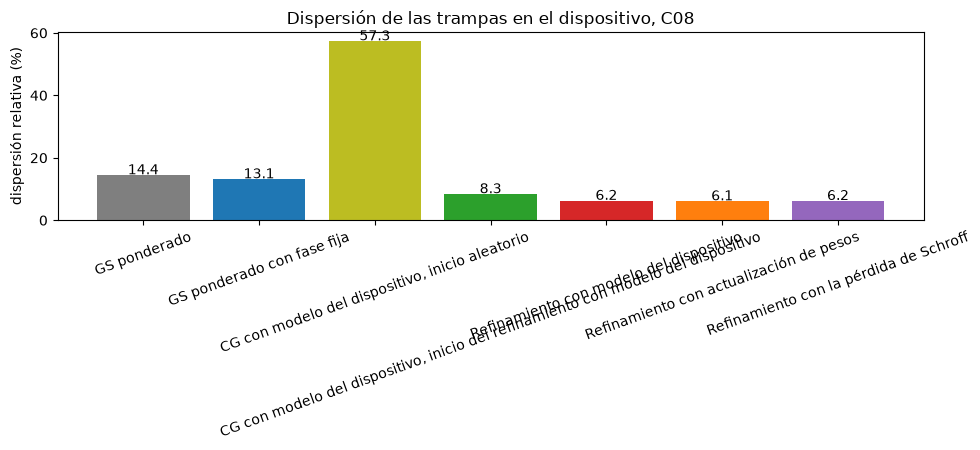

GS ponderado: 14.424 %
GS ponderado con fase fija: 13.132 %
CG con modelo del dispositivo, inicio aleatorio: 57.314 %
CG con modelo del dispositivo, inicio del refinamiento con modelo del dispositivo: 8.349 %
Refinamiento con modelo del dispositivo: 6.240 %
Refinamiento con actualización de pesos: 6.086 %
Refinamiento con la pérdida de Schroff: 6.190 %


In [10]:
# la dispersión de las trampas en el dispositivo: promedio de dos semillas para GS ponderado con fase fija y WGS con
# modelo del dispositivo, primera semilla para GS ponderado y CG con modelo del dispositivo
fig, ax = plt.subplots(figsize=(10, 4.6))
bars = {
    "GS ponderado": on_device(ideal_runs["GS ponderado"].phi, setup, traps, device)[2],
    "GS ponderado con fase fija": m07_numbers[:, 2].mean(),
    "CG con modelo del dispositivo, inicio aleatorio": cg_cold[2],
    "CG con modelo del dispositivo, inicio del refinamiento con modelo del dispositivo": cg_numbers[2],
    "Refinamiento con modelo del dispositivo": b1_numbers[:, 2].mean(),
    "Refinamiento con actualización de pesos": variant_numbers["con la actualización de pesos"][:2, 2].mean(),
    "Refinamiento con la pérdida de Schroff": variant_numbers["pérdida de error normalizado (Schroff et "
        "al.)"][:2, 2].mean(),
}
ax.tick_params(axis="x", labelrotation=20)
ax.bar(list(bars), list(bars.values()), color=["C7", "C0", "C8", "C2", "C3", "C1", "C4"])
for k, value in enumerate(bars.values()):
    ax.text(k, value + 0.3, f"{value:.1f}", ha="center")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Dispersión de las trampas en el dispositivo, C08")
fig.tight_layout()
plt.show()
for name, value in bars.items():
    print(f"{name}: {value:.3f} %")

De los métodos que parten de una fase de Gerchberg-Saxton ponderado, la dispersión baja con cuánto del dispositivo conoce el método. GS ponderado, que no conoce nada de él, tiene una dispersión de 14,4 por ciento y GS ponderado con fase fija, que converge en el modelo ideal, 13,1 por ciento en el promedio de dos semillas; ambos se juzgaron a sí mismos en el modelo ideal en 1,262 y 0,005 por ciento, y cien iteraciones no cambiaron un dígito del resultado de GS ponderado con fase fija en el dispositivo. CG con modelo del dispositivo, el gradiente conjugado a través del operador de crosstalk, depende de su inicio: desde su propio inicio aleatorio 12 iteraciones lo dejan en 57,3 por ciento, una corrida sin converger, y desde el inicio que usa el refinamiento, 12 iteraciones de GS ponderado, los mismos 12 pasos de gradiente lo llevan a 8,3 por ciento en la primera semilla, y 40 pasos lo dejan en 8,5. El refinamiento, que da sus pasos a través del modelo del dispositivo después de ese inicio, termina en 6,2 por ciento en el promedio de dos semillas, y las dos variantes terminan en 6,1 (con la actualización de pesos) y 6,2 por ciento (con la pérdida de Schroff), a la misma altura que el valor por defecto con la precisión de la figura; la salida bajo ella lista los valores. La figura no muestra la eficiencia que paga cada método, que imprime la tabla de arriba.

La segunda figura tiene dos paneles. A la izquierda, la razón de la dispersión de GS ponderado con fase fija a la del refinamiento con modelo del dispositivo contra el ancho del crosstalk, de ninguno al más fuerte. A la derecha, la eficiencia de ambos.

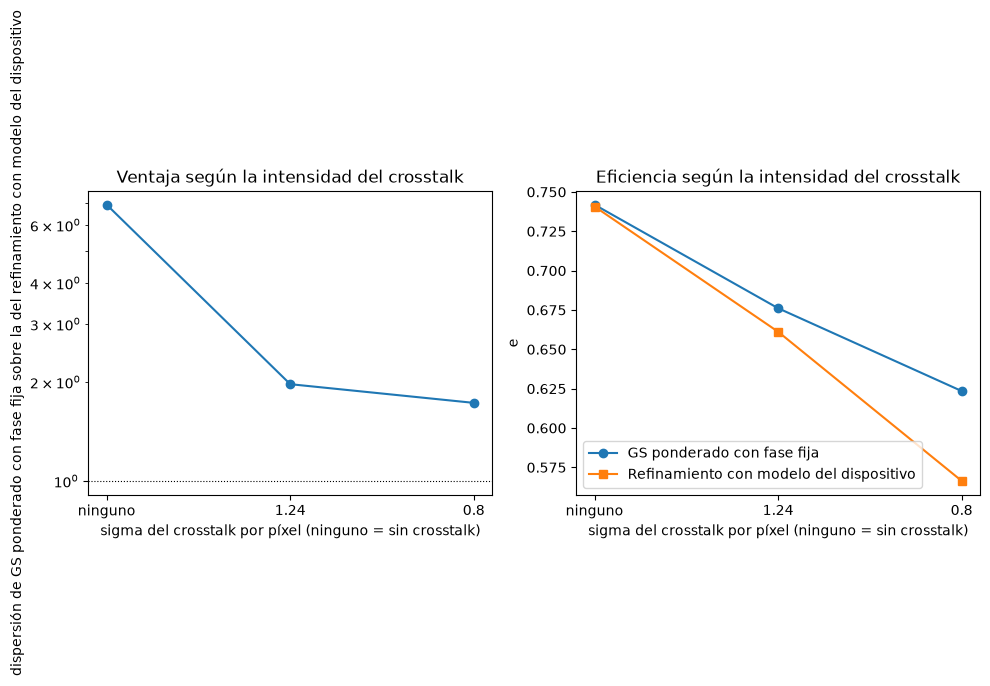

In [11]:
# la razón de las dos dispersiones según la intensidad del crosstalk, y la eficiencia que conserva cada método
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
labels = list(rows)
ax1.semilogy(labels, [rows[k][0][2] / rows[k][1][2] for k in labels], "o-")
ax1.axhline(1.0, color="k", lw=0.8, ls=":")
ax1.set_xlabel("sigma del crosstalk por píxel (ninguno = sin crosstalk)")
ax1.set_ylabel("dispersión de GS ponderado con fase fija sobre la del refinamiento con modelo del dispositivo")
ax1.set_title("Ventaja según la intensidad del crosstalk")
ax2.plot(labels, [rows[k][0][0] for k in labels], "o-", label="GS ponderado con fase fija")
ax2.plot(labels, [rows[k][1][0] for k in labels], "s-", label="Refinamiento con modelo del dispositivo")
ax2.set_xlabel("sigma del crosstalk por píxel (ninguno = sin crosstalk)")
ax2.set_ylabel("e")
ax2.set_title("Eficiencia según la intensidad del crosstalk")
ax2.legend()
fig.tight_layout()
plt.show()

La ventaja no es solo un efecto del crosstalk. Sin ningún crosstalk, con solo 4 bits, un factor de llenado de 0,85 y parpadeo, GS ponderado con fase fija tiene una dispersión de 3,953 por ciento y el refinamiento 0,572, una razón de 6,91, porque el refinamiento ve también el cuantizador y la apertura. A medida que crece el crosstalk ambos empeoran y la razón baja: 1,97 con el ancho del caso, 1,24, y 1,73 con 0,8, donde el refinamiento devuelve su tercer iterado con una dispersión de 14,215 por ciento frente a 24,540. El panel derecho muestra el precio. Sin crosstalk las dos eficiencias difieren en 0,0011 (0,7407 frente a 0,7418); con 1,24 el refinamiento tiene 0,6612 frente a 0,6761, y con 0,8 tiene 0,5664 frente a 0,6235, una razón de 0,908, cercana al piso de 0,9 de la eficiencia del arranque que impone la salvaguarda: con crosstalk fuerte la uniformidad que compra el refinamiento cuesta cerca de una décima de la luz. El barrido usa una semilla por punto y un número fijo de pasos, y no dice nada de dispositivos con otra profundidad de bits.

### Úsalo con tus propios datos

El método propuesto toma lo que un desarrollador puede medir o leer en una hoja de datos: el número de bits de fase, el ancho y la nitidez del crosstalk del cristal líquido, el factor de llenado y el parpadeo. Entran por un solo objeto, `Device`, cuyos campos son los que el registro del contrato 1 lleva en su bloque `device` (`bit_depth`, `crosstalk` como el par $(\sigma, q)$, `fill_factor`, `flicker_rad`); un `crosstalk` igual a `None` apaga esa etapa. La celda siguiente escribe un dispositivo que no es el de C08, 6 bits con un crosstalk más suave de ancho 1,5 y llenado 0,9, y un arreglo que tampoco es el de C08, 16 trampas en un anillo de 20 um con la función `ring`. Corre GS ponderado con fase fija y el refinamiento con modelo del dispositivo desde la misma semilla, lee ambos en el dispositivo con la función `on_device` de este notebook (el promedio de cuatro sorteos del parpadeo) e imprime la dispersión que GS ponderado con fase fija informa de sí mismo, la que cree, junto a la dispersión que muestra el dispositivo. La llamada del refinamiento con modelo del dispositivo es la de la sección de evidencia: `b1_device_wgs.run(setup, target, device=..., budget=Budget(4), rng=...)`, donde el presupuesto cuenta iteraciones externas de tres pasos de gradiente conjugado. La última línea de la celda ejecuta la misma llamada con `weights=True`.

In [12]:
# un dispositivo propio: valores de una hoja de datos o de una calibración, como el Device del motor
mine_device = Device(bit_depth=6, crosstalk=(1.5, 1.8), fill_factor=0.9, flicker_rad=0.03)
mine_traps = ring(16, 20.0)
my_target = Target.from_traps(mine_traps)
print(f"{len(mine_traps)} trampas en un anillo de 20 um, dispositivo: {mine_device.bit_depth} bits, "
      f"crosstalk {mine_device.crosstalk}")
my_m07 = m07_phase_fixed_wgs.run(setup, my_target, budget=budget, rng=Rng(seeds[0]))
my_b1 = b1_device_wgs.run(setup, my_target, device=mine_device, budget=Budget(4), rng=Rng(seeds[0]))
my_w = b1_device_wgs.run(setup, my_target, device=mine_device, budget=Budget(4), rng=Rng(seeds[0]), weights=True)
my_read = {"GS ponderado con fase fija": on_device(my_m07.phi, setup, mine_traps, mine_device),
           "Refinamiento con modelo del dispositivo": on_device(my_b1.phi, setup, mine_traps, mine_device)}
self_judged = my_m07.history[-1]["rel_std"]
print(f"GS ponderado con fase fija se juzga a sí mismo en sigma = {self_judged:.3f} %")
for name, row in my_read.items():
    print(f"{name} en el dispositivo: e = {row[0]:.4f}, u = {row[1]:.4f}, sigma = {row[2]:.3f} %")
print(f"rho = "
    f"{my_read['GS ponderado con fase fija'][2] / my_read['Refinamiento con modelo del dispositivo'][2]:.2f}")
my_w_row = on_device(my_w.phi, setup, mine_traps, mine_device)
print(f"con la actualización de pesos: e = {my_w_row[0]:.4f}, u = {my_w_row[1]:.4f}, sigma = {my_w_row[2]:.4f}")

16 trampas en un anillo de 20 um, dispositivo: 6 bits, crosstalk (1.5, 1.8)
GS ponderado con fase fija se juzga a sí mismo en sigma = 0.000 %
GS ponderado con fase fija en el dispositivo: e = 0.5573, u = 0.8144, sigma = 13.154 %
Refinamiento con modelo del dispositivo en el dispositivo: e = 0.5544, u = 0.9809, sigma = 0.945 %
rho = 13.92
con la actualización de pesos: e = 0.5525, u = 0.9870, sigma = 0.7157


GS ponderado con fase fija juzga su propio holograma con una dispersión de 0,000 por ciento en el modelo ideal, y el dispositivo muestra 13,154 por ciento, con una eficiencia de 0,5573 y una uniformidad de 0,8144. El refinamiento en el mismo dispositivo obtiene 0,945 por ciento, una uniformidad de 0,9809 y una eficiencia de 0,5544, de modo que la razón $\rho$ de las dos dispersiones es 13,92 y el costo en eficiencia es medio por ciento (0,5544 frente a 0,5573). La razón es mayor que el 2,1 de C08, por un motivo que predice el barrido de crosstalk: con el crosstalk más suave de 1,5 el difuminado es más débil, los pasos de gradiente pueden deshacer la mayor parte de él, y las 16 trampas de un anillo simétrico dejan poco que combatir al lazo. La última línea de la salida ejecuta la misma llamada con la actualización de pesos activa: da 0,716 por ciento, menos que los 0,945 del valor por defecto, donde en C08 no cambió nada y en la tarea de aceptación del producto empeora la dispersión. La razón no es entonces una propiedad del método sino del par formado por el dispositivo y el arreglo, y una afirmación del tamaño de la del notebook, un factor de cerca de dos, debe volver a medirse para cada dispositivo, con y sin la actualización de pesos. La figura dibuja los tres números que importan: lo que cree el método de modelo ideal, lo que el dispositivo muestra de él, y lo que recupera el refinamiento.

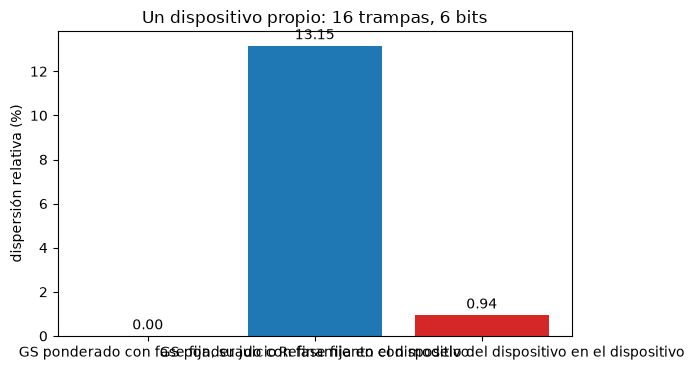

In [13]:
# lo que el método cree contra lo que muestra el dispositivo, y lo que el refinamiento con modelo del dispositivo
# recupera
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = ["GS ponderado con fase fija, su juicio", "GS ponderado con fase fija en el dispositivo",
          "Refinamiento con modelo del dispositivo en el dispositivo"]
values = [self_judged, my_read["GS ponderado con fase fija"][2], my_read["Refinamiento con modelo del dispositivo"][2]]
ax.bar(labels, values, color=["C7", "C0", "C3"])
for k, value in enumerate(values):
    ax.text(k, value + 0.3, f"{value:.2f}", ha="center")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Un dispositivo propio: 16 trampas, 6 bits")
fig.tight_layout()
plt.show()

La primera barra es cero porque el método itera hasta que el modelo ideal es perfectamente uniforme en este arreglo simétrico, la segunda es el mismo holograma en el dispositivo y la tercera es la del refinamiento con modelo del dispositivo: un método que se juzga solo por su propio historial informa un holograma perfecto que el dispositivo muestra en 13 por ciento. Cuatro revisiones para un dispositivo propio, en orden. Primero, que los campos de `Device` salgan de una medición, porque un ancho de crosstalk supuesto cambia la razón de cerca de 1 a grande, como mostró el barrido de arriba. Segundo, que el holograma se lea en el dispositivo y no en el modelo ideal, con varios sorteos del parpadeo. Tercero, que el costo en eficiencia del refinamiento con modelo del dispositivo se cite junto a su ganancia, aquí medio por ciento. Cuarto, que el resultado se repita en más de una semilla y un arreglo antes de afirmarlo, lo que esta sección no hace: muestra la llamada y la lectura en un arreglo, y la afirmación del notebook descansa en las ocho semillas contra GS ponderado con fase fija, las dos semillas contra CG con modelo del dispositivo y el barrido de la sección de evidencia. Los límites son los que ahí se nombran: el refinamiento con modelo del dispositivo es para trampas puntuales en el plano focal, necesita que el modelo del dispositivo sea correcto y, con el crosstalk más fuerte del barrido conserva una razón de 1,73 pero cede cerca de una décima de la luz.

## Resultados

**Respuesta:** Sí frente a ambas líneas base en este dispositivo, y la ganancia viene del modelo del dispositivo en los pasos, no de la actualización de pesos ni de la pérdida. En el dispositivo de C08 los métodos de modelo ideal se equivocan sobre sí mismos: el Gerchberg-Saxton ponderado de fase fija juzga su propio holograma con una dispersión de 0,005 por ciento y el dispositivo muestra 13,349 por ciento, y 100 iteraciones en vez de 30 no cambian nada. El refinamiento por gradiente conjugado con modelo del dispositivo, con 4 iteraciones externas de 3 pasos de gradiente conjugado después de 12 iteraciones de GS ponderado, llega a 6,240 por ciento en promedio de dos semillas (5,696 a 6,785), frente a 13,132 por ciento de GS ponderado con fase fija (12,915 a 13,349), un factor de 2,1 con 0,978 de su eficiencia; la uniformidad es 0,8637 frente a 0,7086. Con ocho semillas la razón de las dispersiones tiene una mediana de 2,10, un rango de 1,72 a 2,41 y un intervalo bootstrap de 95 por ciento de la mediana de 1,78 a 2,25, con el refinamiento al menos dos veces más uniforme en 4 de las 8 semillas y con una mediana de 0,983 de la eficiencia de GS ponderado con fase fija. La línea base más fuerte, el gradiente conjugado a través del operador de crosstalk, con el mismo inicio y los mismos 12 pasos de gradiente, llega a 8,349 por ciento en la primera semilla y 7,743 en la segunda, con eficiencias de 0,6712 y 0,6768, donde el refinamiento tiene 6,785 y 5,696 por ciento: su dispersión es menor por un factor de 1,23 y 1,36, con 0,985 y 0,984 de la eficiencia de CG con modelo del dispositivo. Cuarenta iteraciones de CG con modelo del dispositivo desde el primer inicio lo dejan en 8,508 por ciento, no más bajo que con 12, de modo que más iteraciones no cierran la brecha. Las dos variantes no mueven el resultado en este dispositivo: con la actualización de pesos la mediana de la dispersión en ocho semillas es 6,316 por ciento frente a 6,238 del valor por defecto (razones por semilla de 0,92 a 1,06), y con la pérdida de error normalizado de Schroff et al. es 6,222 por ciento (razones de 0,99 a 1,03, la misma eficiencia en la mediana), de modo que aquí la pérdida publicada más cercana no es peor que la del producto. La ventaja depende del dispositivo: 6,91 veces sin crosstalk, 1,97 con el crosstalk del caso y 1,73 con un ancho de 0,8, donde el refinamiento conserva 0,908 de la eficiencia de GS ponderado con fase fija (0,5664 frente a 0,6235). En un anillo de 16 trampas con un dispositivo de 6 bits la razón es 13,92, y la actualización de pesos, que no cambió nada en C08, baja allí la dispersión de 0,945 a 0,716 por ciento.

## Resumen

Un holograma calculado para un SLM ideal se equivoca sobre sí mismo en un dispositivo con 4 bits y crosstalk, por un factor de 11 en Gerchberg-Saxton ponderado y por órdenes de magnitud en la variante de fase fija, y más iteraciones no lo reparan. Dar pasos de gradiente conjugado a través del modelo del dispositivo después de un inicio ponderado, como hace el refinamiento por gradiente conjugado con modelo del dispositivo, baja la dispersión de Gerchberg-Saxton ponderado de fase fija por un factor mediano de 2,10 en ocho semillas con un costo de cerca de 2 por ciento de la eficiencia, y supera al gradiente conjugado con modelo del dispositivo desde el mismo inicio y con el mismo número de pasos por un margen menor (1,23 y 1,36). Ni la actualización de pesos ni la elección entre la pérdida del producto y la pérdida de error normalizado de Schroff et al. cambian la dispersión en este dispositivo; la actualización de pesos sí la cambia en otras tareas (baja la dispersión de un anillo de 16 trampas y deja la dispersión de la tarea de aceptación del producto cerca de 7 veces peor), de modo que el valor por defecto es una medición que se repite para cada dispositivo y arreglo. Con crosstalk fuerte la ganancia se mantiene en 1,73 pero cuesta cerca de una décima de la luz. Lo que aquí no se prueba es un gradiente conjugado ejecutado más allá de 40 iteraciones, otra profundidad de bits o factor de llenado, parpadeo en el lazo, más de dos semillas para la comparación con el gradiente conjugado, y las redes mayores del benchmark del producto, donde el refinamiento cumple ambos umbrales de la afirmación (un factor de 2 con 0,9 de la eficiencia) en cuatro de seis geometrías y no los cumple en la red de 10 x 10 ni en el conjunto cuasi periódico (datos del manuscrito del método, no recalculados aquí).

## Referencias

- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.
- Kim, Keesling, Omran, Levine, Bernien, Greiner, Lukin y Englund, "Large-scale uniform optical focus array generation with a phase spatial light modulator", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.

- Nogrette et al., "Single-atom trapping in holographic 2D arrays of microtraps with arbitrary geometries", Physical Review X 4, 021034 (2014), https://arxiv.org/abs/1402.5329.
- Persson, Engstrom y Goksor, "Reducing the effect of pixel crosstalk in phase only spatial light modulators", Optics Express 20, 22334 (2012), https://doi.org/10.1364/OE.20.022334.
